# EUR/USD volatility with path signatures: new FX channels

A cleaned, FX-only version of `Mihika/volatility_experiments.ipynb`. The question is the same: do
path signatures of the recent hourly path help forecast volatility, beyond HAR and beyond
signature-free features built from the *same* window? What is new:

- **Channels built for FX**, from the hourly bars (`forecast_data.fx_hourly_channels`, past data only):
  - `price_sa`: log price rebuilt from **time-of-day-adjusted returns**. Each hour's return is divided by
    how volatile that hour of the week (New York time) usually is, so the path shows unusual moves, not
    the clock (Asia / London / New York sessions, the 17:00 rollover).
  - `range_sa`: the hourly high-low range, adjusted the same way.
  - `spread`: the **abnormal bid-ask spread**, log spread minus its usual level for that hour (0 = normal,
    above 0 = wider than usual). Liquidity drying up often comes before volatility.
  - `activity`: Dukascopy volume, as before.
- **Two targets**: volatility (as before) and **volatility direction**: will volatility over the next
  h days be higher than over the last h days?
- **One horizon set**: 1 and 5 trading days, with daily-bar targets and baselines and signatures from the
  hourly path (the `*_i` horizons of the old notebook).

What was removed from the old notebook, and why:

| Removed | Why |
|---|---|
| Daily-path signature models | A 22-bar daily path is too short to have much shape; all new channels are hourly |
| 22-day horizon | About 160 non-overlapping windows since 2012: too few to judge |
| HMM anomaly flag section | Added nothing; replaced by the anomaly study |
| Signature-settings sweep (5 extra runs) | Overlaps the ablations; depth 3 + lead-lag was at or near the best on crypto |
| GARCH, LSTM, XGBoost/MLP on stats | GARCH loses to HAR; the LSTM/MLP tie Ridge at much higher cost |
| Drawdown section, calendar dummies, tick counts | Not part of this round |

- **More pairs** (section 9): the same run on GBP/USD, USD/JPY and AUD/USD, to see whether the EUR/USD
  result is specific to one pair.

**Order:** sections 1-6, 8 and 9 run on their own. Section 7 (anomaly score in the forecasts) needs
`anomaly_fx.ipynb` to have run first.

In [2]:
import logging
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import fx_lab as L
from fx_lab import ex, rp

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(message)s", datefmt="%H:%M:%S", force=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

QUICK = False  # True: data from 2021 and few epochs, to check that everything runs (results in *_quick)
print("EUR/USD hourly bars through", L.END, "(end of the last finished month)")

EUR/USD hourly bars through 2026-10-31 (end of the last finished month)


## 1. Data

Hourly EUR/USD mid prices with the bid-ask spread, from Dukascopy's BID and ASK hourly candle files
(two downloads per month, cached in `Mihika/data/dukascopy/*_1h_ba_*`). The first run downloads about
360 files and Dukascopy rate-limits, so it can take an hour; after that it is instant. Runs stop at the
end of the last finished month, so the slow tick-file fallback for the current month is never used.

Check that the adjustment does what it should: after it, the |return| and range lines are roughly flat
across the day, and the abnormal spread is centred on zero at every hour.

92,480 hourly bars, 2012-01-01 22:00:00+00:00 to 2026-10-30 20:00:00+00:00; median spread 0.28 bp


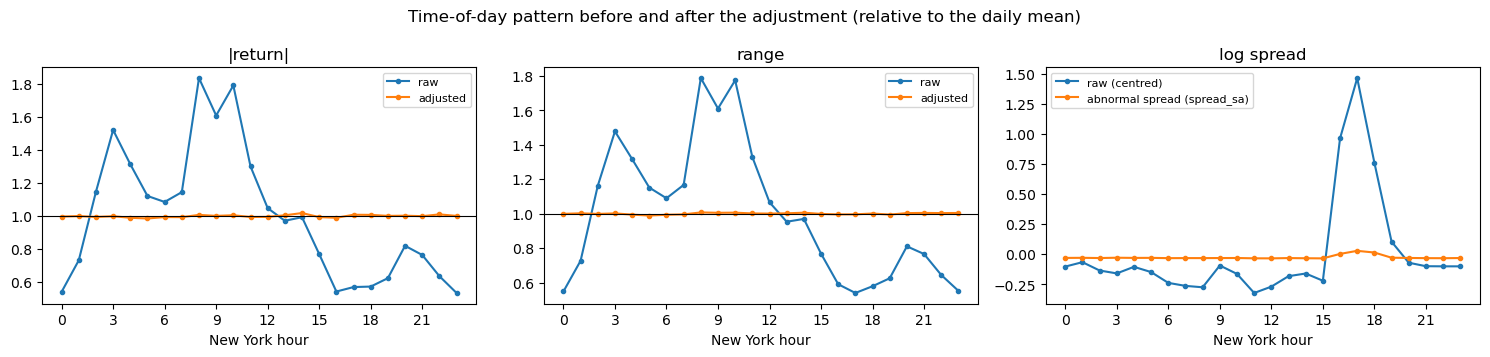

In [3]:
hourly = L.load_hourly(start="2021-01-01" if QUICK else L.START)
print(f"{len(hourly):,} hourly bars, {hourly.index[0]} to {hourly.index[-1]}; "
      f"median spread {1e4 * hourly.spread.median():.2f} bp")
L.plot_seasonality(hourly); plt.show()

## 2. Run the volatility forecasts

Fixed in advance (not tuned here): depth-3 signatures with lead-lag and time, the hourly path over the
last 22 trading days, channels `price_sa, activity, range_sa, spread`, 3 expanding purged folds.

| Model | What it is |
|---|---|
| Mean, HAR-RV-L | Benchmarks (HAR on daily realized variance with a leverage term) |
| HAR-RV-L calibrated | HAR with its average bias removed; anything that only fixes HAR's level ties with it |
| HAR-RV-L (intraday RV) | HAR on hourly realized variance: the strong baseline |
| Ridge \| stats | Ridge on summary statistics of the daily window |
| Ridge \| intraday signature | Ridge on the signature of the hourly path |
| Ridge \| intraday lag bank (matched) | Same increments as flat lagged terms, exactly as many columns: is it the signature, or the information? |
| Ridge \| intraday multiscale stats | Hand-built realized-variance features at several scales from the same window |
| Ridge \| intraday signature + HAR-RV | Does the signature add anything on top of the strong baseline? |
| MLP \| intraday signature / lag bank | The same comparison with a nonlinear learner |

Ablations (Ridge on the hourly signature, same rows and folds) run in the same pass: signature levels,
augmentation, and the channel settings in `L.CHANNEL_ABLATIONS`. Finished horizons are skipped on re-run.

In [4]:
cfg = L.vol_config(quick=QUICK)
ex.run_all(cfg, subprocess_per_horizon=True)
res = rp.load_results(cfg.output_dir)
pd.DataFrame(res.meta).T[["n_rows", "horizon_rows", "n_folds", "first_time", "last_time", "seconds"]]

15:40:47 | [1d_i] already complete, skipping (resume=True)
15:40:49 | [5d_i] already complete, skipping (resume=True)


,n_rows,horizon_rows,n_folds,first_time,last_time,seconds
1d_i,3318,1,3,2012-01-30 22:00:00+00:00,2026-10-28 22:00:00+00:00,509.2
5d_i,3314,5,3,2012-01-30 22:00:00+00:00,2026-10-21 22:00:00+00:00,1472.3


## 3. Ranking

Fold-mean RMSE; `Pct_vs_HAR` > 0 = better than HAR-RV-L. Then pooled out-of-sample RMSE with
Diebold-Mariano tests against the best model and against HAR-RV-L (lag = the horizon in rows).

In [5]:
summ = rp.summary_table(res)
display(summ.style.format({"Mean_RMSE": "{:.6g}", "Fold_SD": "{:.6g}", "Pct_vs_Mean": "{:.1f}", "Pct_vs_HAR": "{:.1f}"}))
for hk in res.meta:
    print(ex.HORIZON_LABELS[hk])
    display(rp.dm_table(res, hk).style.format(precision=4))

,Horizon,Model,Mean_RMSE,Fold_SD,Pct_vs_Mean,Pct_vs_HAR,Rank
0,1 day (intraday paths),Ridge | intraday multiscale stats,0.00182672,0.000306947,16.3,2.8,1
1,1 day (intraday paths),HAR-RV-L calibrated,0.00183196,0.00031986,16.1,2.5,2
2,1 day (intraday paths),HAR-RV-L,0.0018798,0.000322894,13.9,0.0,3
3,1 day (intraday paths),HAR-RV-L (intraday RV),0.00188733,0.000308517,13.6,-0.4,4
4,1 day (intraday paths),Ridge | stats,0.00189094,0.000264763,13.4,-0.6,5
5,1 day (intraday paths),Ridge | intraday signature + HAR-RV,0.00189533,0.000266615,13.2,-0.8,6
6,1 day (intraday paths),Ridge | intraday signature,0.00190303,0.000262421,12.8,-1.2,7
7,1 day (intraday paths),Ridge | intraday lag bank (matched),0.00201682,0.000297906,7.6,-7.3,8
8,1 day (intraday paths),Mean,0.00218352,0.000223749,0.0,-16.2,9
9,1 day (intraday paths),MLP | intraday lag bank (matched),0.00224935,0.000191824,-3.0,-19.7,10


1 day (intraday paths)


,Model,Pooled_RMSE,Best,DM_vs_best,p_vs_best,DM_vs_HAR,p_vs_HAR
0,Ridge | intraday multiscale stats,0.0018,True,nan,nan,-3.4088,0.0007
1,HAR-RV-L calibrated,0.0019,False,0.4524,0.6510,-5.8842,0.0000
2,HAR-RV-L,0.0019,False,3.4088,0.0007,nan,nan
3,Ridge | stats,0.0019,False,3.6329,0.0003,0.2994,0.7646
4,HAR-RV-L (intraday RV),0.0019,False,4.5716,0.0000,0.6097,0.5421
5,Ridge | intraday signature + HAR-RV,0.0019,False,3.5682,0.0004,0.5358,0.5921
6,Ridge | intraday signature,0.0019,False,3.8371,0.0001,0.9202,0.3575
7,Ridge | intraday lag bank (matched),0.0020,False,8.1499,0.0000,5.4618,0.0000
8,Mean,0.0022,False,14.5804,0.0000,10.3102,0.0000
9,MLP | intraday lag bank (matched),0.0023,False,13.2741,0.0000,10.6577,0.0000


5 day (intraday paths)


,Model,Pooled_RMSE,Best,DM_vs_best,p_vs_best,DM_vs_HAR,p_vs_HAR
0,HAR-RV-L calibrated,0.0028,True,nan,nan,-3.1134,0.0018
1,HAR-RV-L,0.0029,False,3.1134,0.0018,nan,nan
2,Ridge | intraday multiscale stats,0.0029,False,1.5796,0.1142,0.7027,0.4822
3,HAR-RV-L (intraday RV),0.0029,False,2.6310,0.0085,1.3244,0.1854
4,Ridge | intraday signature + HAR-RV,0.0030,False,2.5661,0.0103,1.7180,0.0858
5,Ridge | intraday signature,0.0030,False,2.7337,0.0063,1.9019,0.0572
6,Ridge | stats,0.0030,False,3.4247,0.0006,2.6564,0.0079
7,Ridge | intraday lag bank (matched),0.0033,False,5.1218,0.0000,4.5380,0.0000
8,Mean,0.0038,False,9.8113,0.0000,8.9755,0.0000
9,MLP | intraday lag bank (matched),0.0039,False,8.3696,0.0000,7.6969,0.0000


## 4. Is it the signature?

Each model against what it must beat, on identical rows. `Pct_better` > 0 = lower RMSE; a small `DM_p`
means the difference is significant. In the figure, green / red = significantly better / worse, grey =
the data cannot tell them apart. The signature has to beat the **matched lag bank** and the
**multiscale stats** for its geometry to matter, and **HAR on intraday RV** to be useful at all.

,Horizon,Model,Versus,RMSE_model,RMSE_versus,Pct_better,DM_stat,DM_p
0,1 day (intraday paths),Ridge | intraday signature,Ridge | intraday lag bank (matched),0.0019,0.0020,5.7261,-5.8436,0.0000
1,1 day (intraday paths),Ridge | intraday signature,Ridge | intraday multiscale stats,0.0019,0.0018,-3.8623,3.8371,0.0001
2,1 day (intraday paths),Ridge | intraday signature,HAR-RV-L (intraday RV),0.0019,0.0019,-0.5757,0.5860,0.5579
3,1 day (intraday paths),Ridge | intraday signature,HAR-RV-L calibrated,0.0019,0.0019,-3.4884,3.9736,0.0001
4,1 day (intraday paths),Ridge | intraday signature + HAR-RV,HAR-RV-L (intraday RV),0.0019,0.0019,-0.1944,0.2045,0.8380
5,1 day (intraday paths),MLP | intraday signature,MLP | intraday lag bank (matched),0.0033,0.0023,-46.3396,9.1117,0.0000
6,1 day (intraday paths),MLP | intraday signature,Ridge | intraday signature,0.0033,0.0019,-72.2961,11.7166,0.0000
7,1 day (intraday paths),HAR-RV-L (intraday RV),HAR-RV-L,0.0019,0.0019,-0.3092,0.6097,0.5421
8,5 day (intraday paths),Ridge | intraday signature,Ridge | intraday lag bank (matched),0.0030,0.0033,10.3771,-4.1160,0.0000
9,5 day (intraday paths),Ridge | intraday signature,Ridge | intraday multiscale stats,0.0030,0.0029,-3.0456,1.2116,0.2257


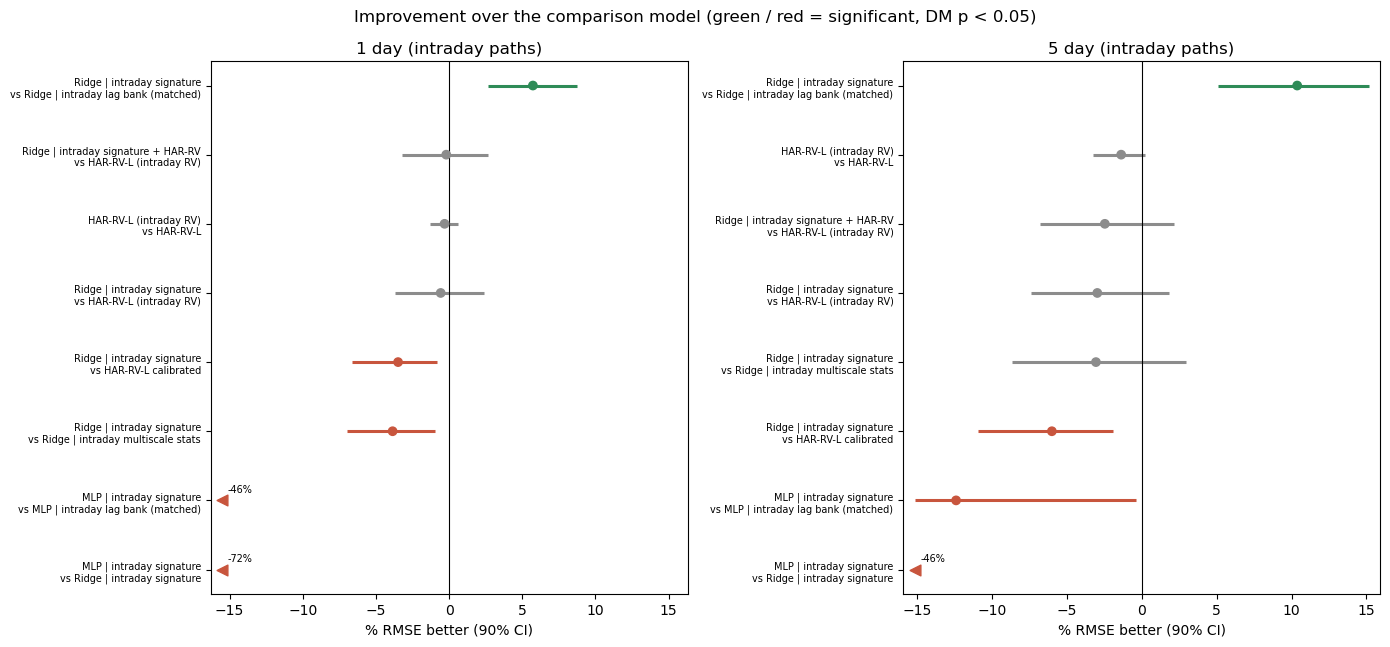

In [6]:
display(rp.pair_table(res, L.VOL_COMPARISONS).style.format(precision=4))
rp.plot_pair_skill(res, rp.as_pairs(L.VOL_COMPARISONS)); plt.show()

**Calibration and stability.** Are the forecasts the right size (points on the diagonal), and is any
gain steady over time or from a few episodes (rolling RMSE relative to HAR-RV-L; below 1 = better)?

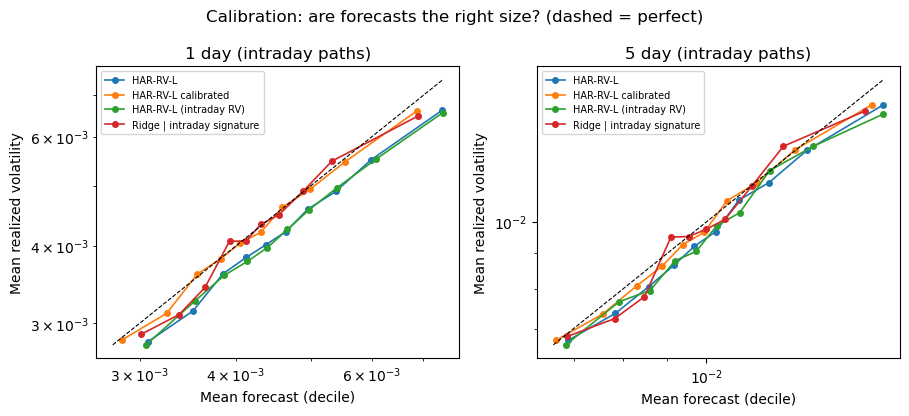

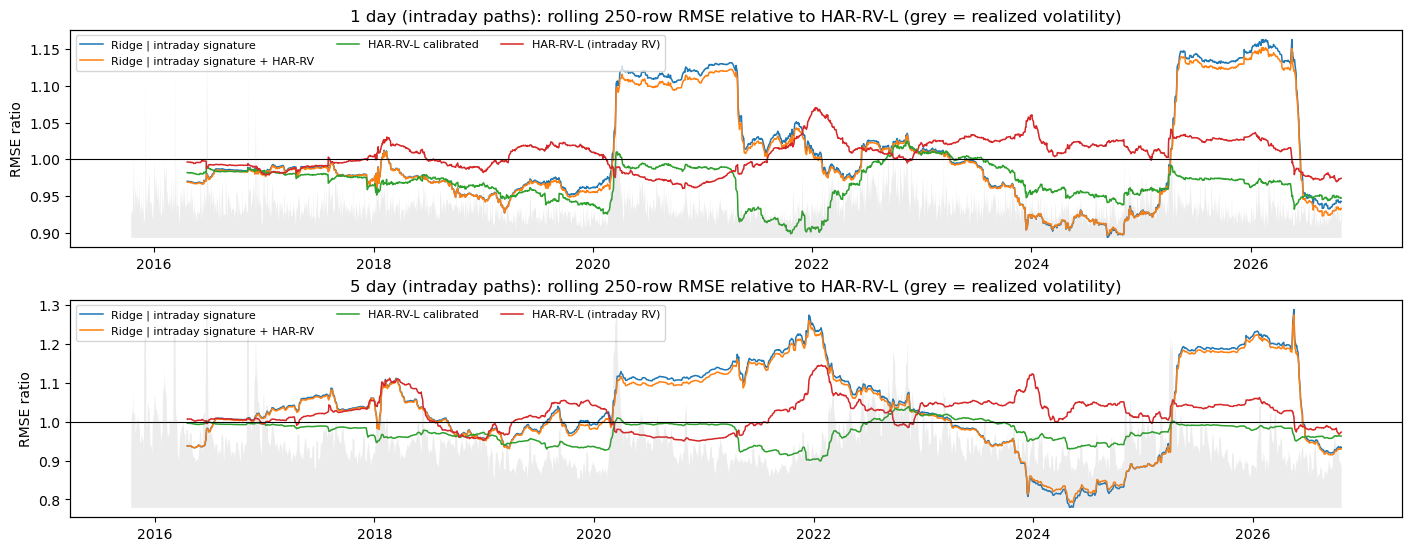

In [7]:
KEY = ["Ridge | intraday signature", "Ridge | intraday signature + HAR-RV", "HAR-RV-L calibrated", "HAR-RV-L (intraday RV)"]
rp.plot_calibration(res, models=("HAR-RV-L", "HAR-RV-L calibrated", "HAR-RV-L (intraday RV)", "Ridge | intraday signature")); plt.show()
rp.plot_error_over_time(res, KEY); plt.show()

## 5. What do the new channels add?

Ridge on the hourly signature under each setting, same rows and folds. `Pct_vs_group_ref` compares
with the first setting of each group: level 1 only, the raw path, and the **original channels** (price,
activity, range: what the previous FX run used). Read the channel rows as:

- *Adjusted, no spread* vs *Original*: the effect of the time-of-day adjustment;
- *Adjusted + spread* vs *Adjusted, no spread*: the effect of the spread channel.

These are descriptive (the main setting was fixed before seeing them). A difference of a few percent is
within noise.

In [8]:
abl = L.ablation_table(res)
display(abl.style.format({"Mean_RMSE": "{:.6g}", "Pct_vs_HAR": "{:.1f}", "Pct_vs_group_ref": "{:.1f}"}))

,Horizon,Experiment,Setting,Mean_RMSE,Pct_vs_HAR,Pct_vs_group_ref
0,1 day (intraday paths),Signature level,L1-1,0.00189256,-0.7,0.0
1,1 day (intraday paths),Signature level,L1-2,0.00187603,0.2,0.9
2,1 day (intraday paths),Signature level,L1-3,0.00190303,-1.2,-0.6
3,1 day (intraday paths),Augmentation,Raw path,0.00190322,-1.2,0.0
4,1 day (intraday paths),Augmentation,Time,0.00191583,-1.9,-0.7
5,1 day (intraday paths),Augmentation,Lead-lag + time,0.00190303,-1.2,0.0
6,1 day (intraday paths),Channels,"Original (price, activity, range)",0.00184715,1.7,0.0
7,1 day (intraday paths),Channels,Adjusted price only,0.00203812,-8.4,-10.3
8,1 day (intraday paths),Channels,"Adjusted, no spread",0.00188,-0.0,-1.8
9,1 day (intraday paths),Channels,Adjusted + spread (main),0.00190303,-1.2,-3.0


## 6. Volatility direction

**Up** = realized volatility over the next h days is above the last h days (about half the rows). Two
ways to predict it, scored on the same out-of-sample rows:

- **From the volatility forecasts** above, with no refit: a forecast above the past level means "up",
  and log(forecast / past level) ranks the rows.
- **Logistic classifiers** fit on the same purged folds: HAR features alone (the reference), and HAR plus
  one representation of the hourly window (intraday HAR-RV, multiscale stats, the matched lag bank, or
  the signature).

`AUC` ranks rows (0.5 = coin flip); `Hit_rate` is the share called correctly. `AUC_vs_ref` is the AUC
minus that of the HAR classifier, with a 90% block-bootstrap interval; `p_one_sided` small = reliably
better. The signature is useful here only if *HAR + signature* beats *HAR + lag bank* and *HAR + intraday
HAR-RV*, not just HAR alone.

15:40:51 | [1d_i] direction already complete, skipping
15:40:51 | [5d_i] direction already complete, skipping
/Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/fx_lab.py:482: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fold_auc = g.groupby("Fold").apply(lambda x: roc_auc_score(x.up, x.score) if 0 < x.up.mean() < 1 else np.nan)
/Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/fx_lab.py:482: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping c

,Horizon,Model,Source,N,Up_rate,AUC,AUC_fold_mean,Hit_rate,AUC_vs_ref,CI_low,CI_high,p_one_sided,Log_loss,Brier
0,1 day (intraday paths),Logit | HAR + intraday HAR-RV,classifier,2489,0.510,0.795,0.795,0.714,0.002,-0.001,0.006,0.178,0.549,0.185
1,1 day (intraday paths),Logit | HAR + intraday multiscale stats,classifier,2489,0.510,0.794,0.795,0.716,0.001,-0.005,0.006,0.414,0.552,0.187
2,1 day (intraday paths),Logit | HAR,classifier,2489,0.510,0.793,0.794,0.710,nan,nan,nan,nan,0.552,0.186
3,1 day (intraday paths),Logit | HAR + intraday signature,classifier,2489,0.510,0.714,0.704,0.641,-0.079,-0.096,-0.065,1.000,0.625,0.216
4,1 day (intraday paths),Logit | HAR + intraday lag bank (matched),classifier,2489,0.510,0.661,0.663,0.615,-0.132,-0.150,-0.115,1.000,0.655,0.232
5,1 day (intraday paths),HAR-RV-L (intraday RV),vol forecast,2489,0.510,0.795,0.795,0.685,0.001,-0.003,0.006,0.340,nan,nan
6,1 day (intraday paths),HAR-RV-L calibrated,vol forecast,2489,0.510,0.793,0.793,0.701,-0.000,-0.002,0.002,0.528,nan,nan
7,1 day (intraday paths),HAR-RV-L,vol forecast,2489,0.510,0.793,0.793,0.680,-0.000,-0.003,0.002,0.590,nan,nan
8,1 day (intraday paths),Ridge | intraday signature + HAR-RV,vol forecast,2489,0.510,0.789,0.789,0.703,-0.004,-0.010,0.002,0.892,nan,nan
9,1 day (intraday paths),Ridge | intraday multiscale stats,vol forecast,2489,0.510,0.789,0.789,0.700,-0.004,-0.012,0.004,0.834,nan,nan


/Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/fx_lab.py:507: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fig, axes = plt.subplots(1, len(hz), figsize=(7 * len(hz), 0.45 * t.groupby("Horizon").size().max() + 1.8),


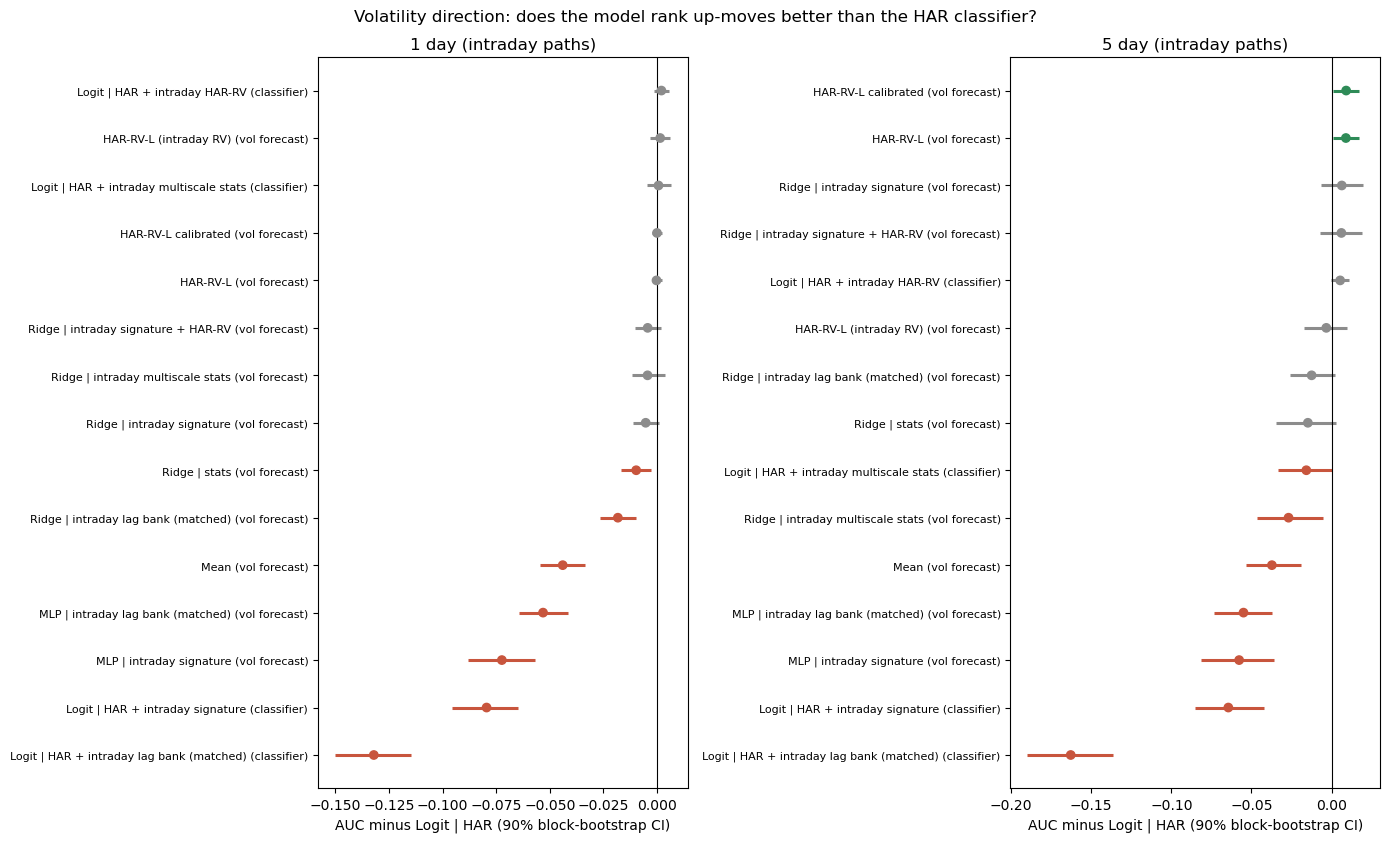

In [9]:
droot = L.run_direction(cfg)
ddf, dmeta = L.load_direction(droot)
dtab = L.direction_table(ddf, dmeta)
display(dtab.style.format(precision=3))
L.plot_direction(dtab); plt.show()

## 7. The anomaly score in the forecasts

Needs `anomaly_fx.ipynb` first: it selects the best signature detector and the best signature-free
detector for each horizon. Each detector's score (its percentile among the training rows) is used
two ways, refit per fold:

- as an extra input to HAR (`HAR-RV-L + anomaly`);
- as a correction of HAR's error (`HAR-RV-L + anomaly residual`).

The decisive comparison is against **HAR-RV-L calibrated**: on crypto, most of the apparent gain from
the anomaly score was HAR's average bias, which a plain rescaling removes. `Pct_sig_vs_free` > 0 means
the signature detector's version is better than the signature-free one's.

15:41:09 | [1d_i] already complete, skipping (resume=True)
15:41:11 | [5d_i] already complete, skipping (resume=True)


,Horizon,Use,Base,Detector,N_flagged,Pct_all,Pct_flagged,Pct_unflagged,RMSE_base,RMSE_with,DM_p_vs_base,Pct_sig_vs_free,DM_p_sig_vs_free
0,1 day (intraday paths),feature,HAR-RV-L,signature,140,-0.275,-5.400,0.118,0.002,0.002,0.322,-0.254,0.360
1,1 day (intraday paths),feature,HAR-RV-L,signature-free,161,-0.021,1.230,-0.223,0.002,0.002,0.940,nan,nan
2,1 day (intraday paths),residual,HAR-RV-L,signature,140,2.517,3.950,2.411,0.002,0.002,0.000,0.005,0.987
3,1 day (intraday paths),residual,HAR-RV-L,signature-free,161,2.512,0.844,2.787,0.002,0.002,0.000,nan,nan
4,1 day (intraday paths),residual vs calibrated,HAR-RV-L calibrated,signature,140,0.003,-0.233,0.020,0.002,0.002,0.993,0.005,0.987
5,1 day (intraday paths),residual vs calibrated,HAR-RV-L calibrated,signature-free,161,-0.002,0.007,-0.003,0.002,0.002,0.995,nan,nan
6,5 day (intraday paths),feature,HAR-RV-L,signature,100,-0.383,-3.386,-0.043,0.003,0.003,0.424,0.376,0.567
7,5 day (intraday paths),feature,HAR-RV-L,signature-free,245,-0.762,-3.337,0.089,0.003,0.003,0.230,nan,nan
8,5 day (intraday paths),residual,HAR-RV-L,signature,100,1.438,0.695,1.521,0.003,0.003,0.002,-0.132,0.404
9,5 day (intraday paths),residual,HAR-RV-L,signature-free,245,1.568,-0.104,2.118,0.003,0.003,0.000,nan,nan


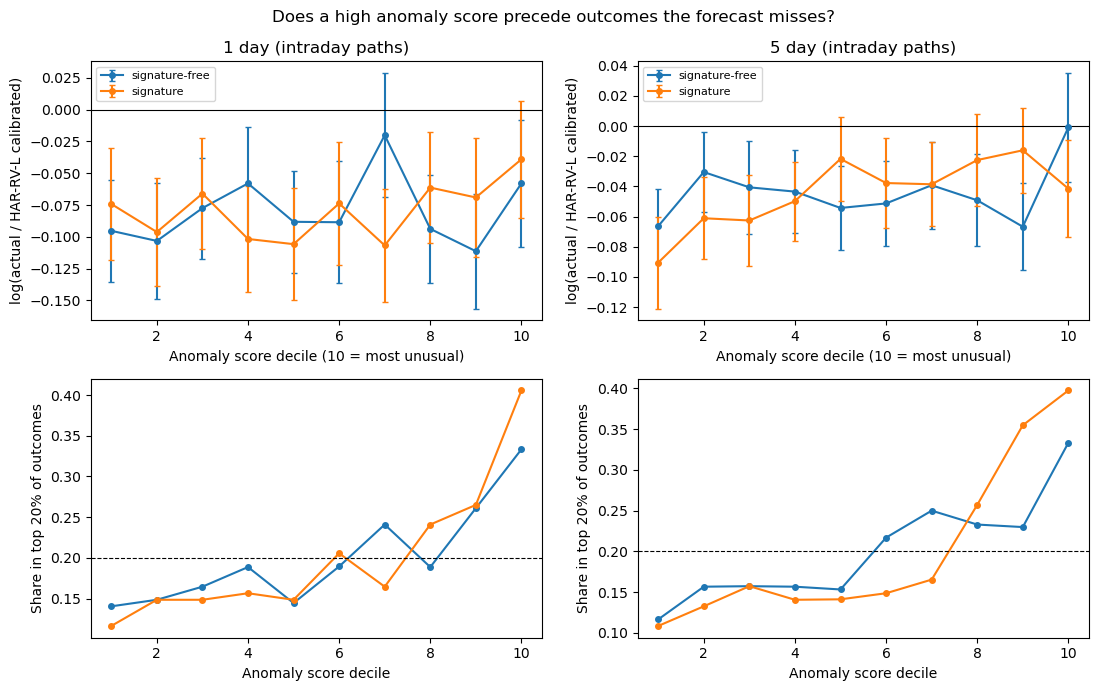

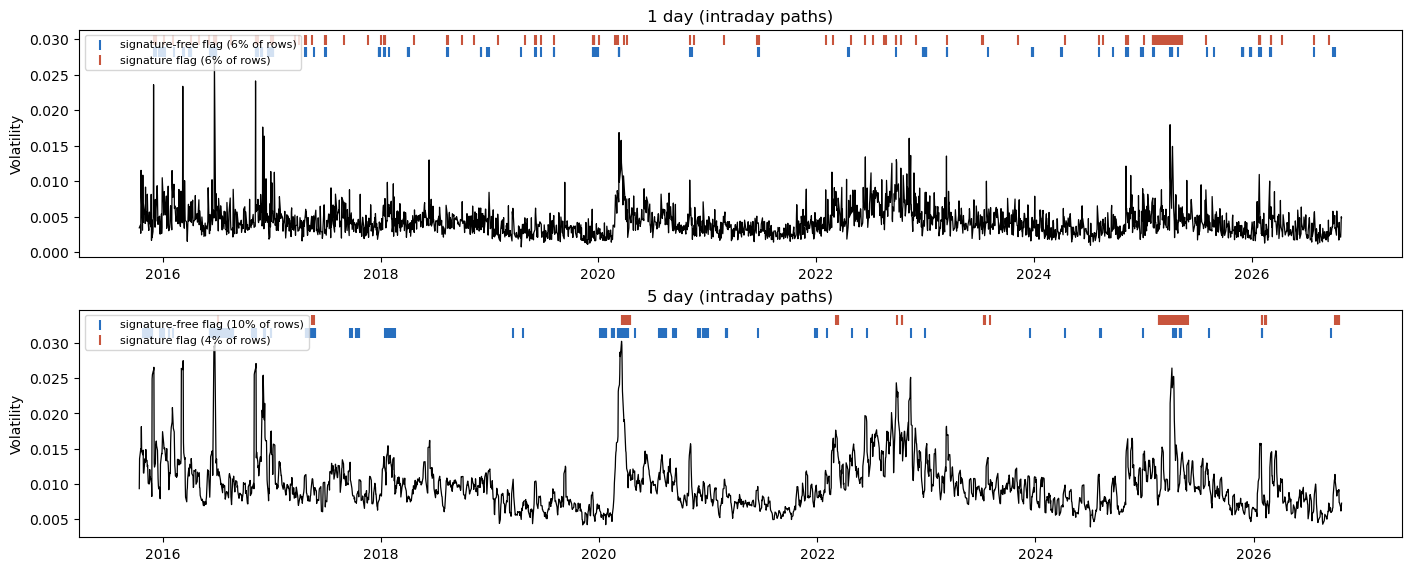

In [10]:
acfg = L.anomaly_config(quick=QUICK)
selection = Path(acfg.output_dir) / "best_configs.json"
if not selection.exists():
    print(f"Run anomaly_fx.ipynb first (no {selection})")
else:
    vcfg = replace(cfg, use_anomaly=True, anomaly_selection=str(selection), run_ablations=False,
                   models=("Mean", "HAR-RV-L", "HAR-RV-L calibrated", *L.ANOMALY_MODELS),
                   output_dir=str(L.RESULTS / ("vol_anomaly_quick" if QUICK else "vol_anomaly")))
    ex.run_all(vcfg, subprocess_per_horizon=True)
    ares = rp.load_results(vcfg.output_dir)
    display(rp.anomaly_effect_table(ares).style.format(precision=3))
    rp.plot_anomaly_response(ares); plt.show()
    rp.plot_anomaly_timeline(ares); plt.show()

## 8. Compared with the previous FX run

The previous run (`Mihika/results/fx/intraday`, original channels) next to this one, for the models
both have. Its rows end on the day it ran, so compare levels, not row by row: the like-for-like
channel comparison is the ablation table in section 5.

In [11]:
prev = L.compare_with_previous(res)
display(prev.style.format(precision=4) if prev is not None else "No previous FX intraday run found.")

,Horizon,Model,Pct_vs_HAR_previous,Pct_vs_HAR_new,Mean_RMSE_previous,Mean_RMSE_new
0,1 day (intraday paths),Ridge | intraday multiscale stats,2.8234,2.8234,0.0018,0.0018
1,1 day (intraday paths),HAR-RV-L calibrated,2.5449,2.5449,0.0018,0.0018
2,1 day (intraday paths),Ridge | intraday signature + HAR-RV,2.0454,-0.8261,0.0018,0.0019
3,1 day (intraday paths),Ridge | intraday signature,1.7370,-1.2356,0.0018,0.0019
4,1 day (intraday paths),HAR-RV-L,0.0000,0.0000,0.0019,0.0019
5,1 day (intraday paths),HAR-RV-L (intraday RV),-0.4008,-0.4008,0.0019,0.0019
6,1 day (intraday paths),Ridge | stats,-0.5928,-0.5928,0.0019,0.0019
7,1 day (intraday paths),Ridge | intraday lag bank (matched),-7.3911,-7.2889,0.0020,0.0020
8,1 day (intraday paths),Mean,-16.1570,-16.1570,0.0022,0.0022
9,5 day (intraday paths),HAR-RV-L calibrated,1.5710,1.5710,0.0028,0.0028


## 9. More currency pairs

Is the EUR/USD result about EUR/USD, or about FX? The same run (same settings, channels, ablations and
direction target) on three more majors. EUR/USD is not recomputed: its results above are reused.

- **First run downloads** each pair's BID and ASK hourly candles, about 360 files per pair under
  Dukascopy's rate limit: up to an hour per pair, then cached. Each pair's run then takes about as long as
  EUR/USD's (about 35 minutes).
- **Resumes**: finished pairs and horizons are skipped, so an interrupted cell can be re-run. Results go to
  `results/pairs/<pair>/`.
- USD/JPY prices are quoted to 3 decimals; the loader handles that (`_dukascopy_point`). The spread
  channel is relative to the price, so it is comparable across pairs.

In [12]:
pair_cfgs = L.run_pairs(L.PAIRS, quick=QUICK)
pair_res = L.load_pairs(pair_cfgs)
print("finished:", ", ".join(pair_res))

15:41:13 | ==== EURUSD ====
15:41:15 | [1d_i] already complete, skipping (resume=True)
15:41:17 | [5d_i] already complete, skipping (resume=True)
15:41:18 | [1d_i] direction already complete, skipping
15:41:18 | [5d_i] direction already complete, skipping
15:41:18 | ==== GBPUSD ====
15:41:20 | [1d_i] rows=3317 stride=1 folds=[(829, 829), (1657, 829), (2486, 830)]
15:41:20 | Fitting log-HAR-RV-L with HAC(5) standard errors
15:41:20 | Fitting log-HAR-RV-L with HAC(5) standard errors
15:41:20 | Fitting log-HAR-RV-L with HAC(5) standard errors
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas

** On entry to SLASCL, parameter number  4 had an illegal value
** On entry to SLASCL, parameter number  4 had an illegal value


/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular ma

** On entry to SLASCL, parameter number  4 had an illegal value
** On entry to SLASCL, parameter number  4 had an illegal value


/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=2.88093e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=1.15178e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/Users/mihikaghaisas/miniforge3/envs/tes

** On entry to SLASCL, parameter number  4 had an illegal value
** On entry to SLASCL, parameter number  4 had an illegal value


... (44 outputs left out)

/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=2.7775e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=8.22248e-09): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=5.57168e-09): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=Fa

** On entry to SLASCL, parameter number  4 had an illegal value
** On entry to SLASCL, parameter number  4 had an illegal value


/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:252: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=8.22248e-09): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/Users/mihikaghaisas/miniforge3/envs/test1/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=3.97779e-09): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/Users/mihikaghaisas/miniforge3/envs/tes

finished: EURUSD, GBPUSD, USDJPY, AUDUSD


**Level.** Fold-mean RMSE, % better than HAR-RV-L (> 0 = better), per pair and horizon. `Signature, original
channels` is the channel-ablation row with price, activity and range: on EUR/USD it did better than the
adjusted channels. If the hourly path carries information on a pair, `HAR on hourly RV` should beat HAR there
too.

,Pair,Horizon,Signature,Signature + HAR-RV,Multiscale stats,HAR on hourly RV,HAR calibrated,"Signature, original channels"
0,EURUSD,1 day (intraday paths),-1.2,-0.8,2.8,-0.4,2.5,1.7
1,EURUSD,5 day (intraday paths),-4.6,-4.1,-1.0,-1.4,1.6,-0.8
2,GBPUSD,1 day (intraday paths),-35.7,-34.2,1.6,0.2,1.7,-8.1
3,GBPUSD,5 day (intraday paths),-51.0,-49.0,1.4,0.0,1.2,-52.0
4,USDJPY,1 day (intraday paths),-0.6,0.6,2.6,0.2,2.5,-0.1
5,USDJPY,5 day (intraday paths),-2.7,-2.1,-0.3,-0.1,1.7,-1.6
6,AUDUSD,1 day (intraday paths),-1.5,-1.2,-0.9,-1.2,1.4,-1.8
7,AUDUSD,5 day (intraday paths),-4.3,-3.8,-2.9,-2.1,0.7,-11.2


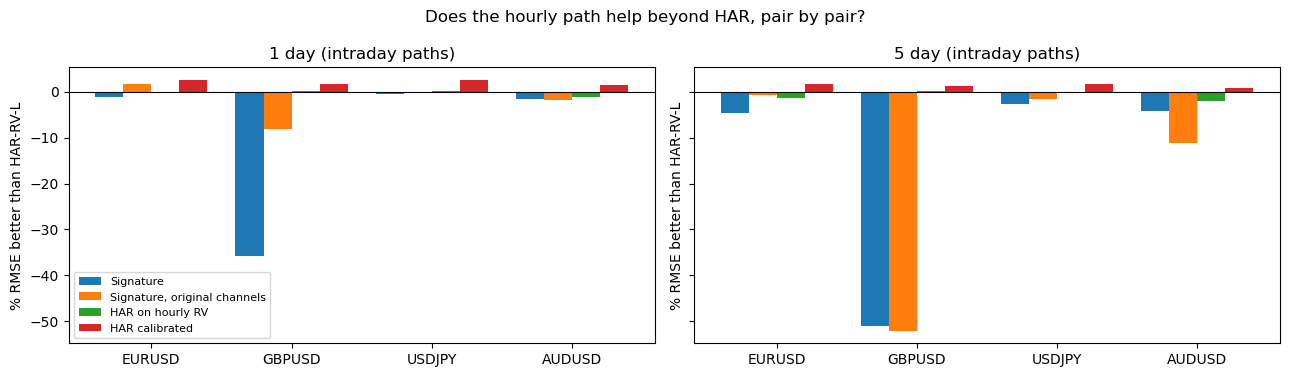

In [13]:
plevel = L.pairs_level_table(pair_res)
display(plevel.style.format(precision=1, subset=plevel.columns[2:]))
L.plot_pairs(plevel); plt.show()

**Tests.** The signature model against each benchmark on identical rows: `Pct_better` > 0 = signature better,
`DM_p` = Diebold-Mariano p-value. The question for each pair: does the signature beat the matched lag bank
(it did on EUR/USD and BTC), and does it beat HAR and calibrated HAR (it did not on EUR/USD)?

In [14]:
ptests = L.pairs_test_table(pair_res)
display(ptests.style.format(precision=3))

**Direction.** AUC of "will volatility rise?", per pair: the HAR classifier, the HAR + signature classifier,
and the HAR and signature volatility forecasts used as direction scores.

In [15]:
pdir = L.pairs_direction_table(pair_cfgs)
display(pdir.style.format(precision=3))

/Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/fx_lab.py:482: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fold_auc = g.groupby("Fold").apply(lambda x: roc_auc_score(x.up, x.score) if 0 < x.up.mean() < 1 else np.nan)
/Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/fx_lab.py:482: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fold_auc = g.groupby("Fold").apply(lambda x: roc_auc_score(x.u

## 10. Save the summary tables

In [16]:
out = L.RESULTS / ("summary_quick" if QUICK else "summary")
out.mkdir(parents=True, exist_ok=True)
summ.to_csv(out / "vol_summary.csv", index=False)
abl.to_csv(out / "vol_ablations.csv", index=False)
dtab.to_csv(out / "vol_direction.csv", index=False)
rp.pair_table(res, L.VOL_COMPARISONS).to_csv(out / "vol_comparisons.csv", index=False)
plevel.to_csv(out / "pairs_level.csv", index=False)
ptests.to_csv(out / "pairs_tests.csv")
pdir.to_csv(out / "pairs_direction.csv")
print("saved to", out)

saved to /Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/results/summary
